# Sujet : Impact des espaces verts publics sur le prix au mètre carré de l'immobilier à Paris

*Projet Python pour la Data Science - Joceran jaillet, Thibault Lefort, Clothilde Migaud*

## Introduction

L'épisode caniculaire de l'été 2026 a montré à quel point les espaces verts publics étaient devenus indispensables pour faire face aux vagues de chaleur de plus en plus fréquentes. Ce fut notamment le cas à Paris, où les parcs publics sont devenus très prisés par les parisiens pour se rafraichir; certains parcs étant même restés ouverts la nuit pour permettre aux habitants de dormir au frais. 

D'après un rapport publié en 2023 par la Chambre régionale des comptes, la politique de végétalisation de Paris vise à adapter la ville au changement climatique, à réduire les îlots de chaleur urbains, à favoriser la biodiversité et à améliorer le cadre de vie des habitants. 
Cela se traduit notamment par le développement d'espaces verts, comme la place de la Catalogne ou le parvis de l'Hôtel de Ville, qui démontre l'importance de tels espaces pour les habitants.

Dans un contexte où les espaces verts semblent devenir un facteur valorisé par les ménages, nous nous interrogeons sur leur impact potentiel sur le prix des logements. 

**Problématique** : Le fait d'habiter à proximité d'un espace vert augmente-t-il la valeur du logement? 

### Sommaire

- **Introduction**

- **I. Création et exploration de la base de données principale**
    - A. Récupération des données
        - _0. Packages et paramètres_
        - _1. Espaces verts parisiens_
        - _2. Ventes immobilières à Paris_
        - _3. Autres bases explorées_
    - B. Nettoyage des données
        - _1. Sélection des données_
        - _2. Harmonisation des types_
        - _3. Valeurs manquantes et atypiques_
        - _4. Variables utiles pour la régression_
        - _5. Harmonisation des noms de colonnes_
        - _6. Variable de période_
        - _7. Création de couches géométriques_
    - C. Export de la base finale

- **II. Visualisations et statistiques descriptives**
    - A. Exploration de la base
        - _1. ..._
        - _2. ..._
    - B. Visualisation des données
    - C. ...

- **III. Modélisation : effet des espaces verts sur le prix du mètre carré à Paris**
    - A. Objectif
    - B. Données et variables du modèle 
        - _1. Chargement de la base_
        - _2. Variables_
    - C. Modèles économétriques 
        - _1. Présentation_
        - _2. Effet estimé de la distance_
        - _3. Interprétation_
    - D. Tests de robustesse
    - E. Conclusion de la modélisation

- **Conclusion**

# I. Création et exploration de la base de données principale

Dans cette partie, nous importons les données brutes, les nettoyons, puis nous les croisons spatialement pour obtenir des bases exploitables.  

| Fichier brut | Description | Source | Mode d'extraction |
|---|---|---|---|
| `espaces_verts.csv` | Inventaire des espaces verts et assimilés de la Ville de Paris : nom, typologie, catégorie, surfaces, contour géographique. | Ville de Paris, Direction des Espaces Verts et de l'Environnement ([lien](https://www.data.gouv.fr/datasets/espaces-verts-et-assimiles/)). | CSV (séparateur `;`) |
| `PJ_75_2021.gpkg` | Parcs et jardins ouverts au public à Paris (millésime 2021), sous forme de polygones. | Ministère de la transition écologique ([lien](https://cartes.gouv.fr/rechercher-une-donnee/dataset/IGNF_PARCS-JARDINS-PUBLICS-OUVERTS-PUBLIC)) | GeoPackage |
| `dvf_plus_d75.csv` | Mutations immobilières du département de Paris (DVF+). | Cerema, DVF+, construit à partir des Demandes de valeurs foncières de la DGFiP ([lien](https://doc-datafoncier.cerema.fr/)). | CSV (séparateur `\|`), téléchargé depuis un Drive partagé avec `gdown` |

Nous obtenonons les bases de données suivantes à l'issue du nettoyage : 

| Fichier nettoyé | Remarques |
|---|---|
| `ev_actuels_nettoyes.csv` | Les résultats de la régression étant peu satisfaisants, nous avons introduit une autre base de données :  `parcs_publics_nettoyee.csv`. Il manque en effet certains espaces publics non gérés par la ville de Paris, par conséquent non présents dans les données. Cela est visible dans la partie visualisation des données. | 
| `parcs_publics_nettoyee.gpkg` | Base utilisée pour la régression linéaire, car plus exhaustive sur les espaces publics parisiens. |
| `dvf_paris_nettoyee` | Pour chaque appartement, on a le prix au mètre carré ainsi qu'un indicateur de mesure de proximité des espaces verts, construits avec la base `ev_actuels_nettoyes.csv`. Ces indicateurs ne seront finalement pas utilisés dans nos analyses car la base `ev_actuels_nettoyes.csv` donne des résultats peu satisfaisants. Dans cette version on conserve les appartements avec dépendances.|
| `dvf_paris_sans_dependances` | Dans cette version on supprime les appartements avec dépendances.|




## A. Récupération des données

### 0. Imports et paramètres

In [51]:
import os
import json
import numpy as np
import pandas as pd
import geopandas as gpd
import gdown
from shapely.geometry import shape

pd.set_option("display.max_columns", None)   # afficher toutes les colonnes

# Se placer à la racine du projet (le dossier qui contient "data"), quel que soit le poste
if not os.path.exists("data") and os.path.exists("../data"):
    os.chdir("..")
print("Dossier de travail :", os.getcwd())

# Paramètres
FILE_DVF_PLUS_ID = "1Mnsnm-OCvw-5zLuVBf6p41NtDChE_yg1"   # identifiant du fichier sur le Drive partagé
FICHIER_LOCAL_DVF_PLUS = "dvf_plus_d75.csv"               # fichier volumineux : à mettre dans le .gitignore
DOSSIER_BRUT = "data/1.data_brute"
DOSSIER_SORTIE = "data/2.data_nettoyee"

Dossier de travail : /Users/clothildemigaud/Projet python 2A /Projet-python-2A-


### 1. Espaces verts parisiens

In [52]:
ev_actuels = pd.read_csv(f"{DOSSIER_BRUT}/espaces_verts.csv", sep=";", encoding="utf-8")

n_ev_brut = len(ev_actuels)
print(f"Espaces verts (brut) : {ev_actuels.shape[0]} lignes, {ev_actuels.shape[1]} colonnes")
display(ev_actuels.head())

Espaces verts (brut) : 2535 lignes, 31 colonnes


,Identifiant espace vert,Nom de l'espace vert,Typologie d'espace vert,Catégorie,Adresse - Numéro,Adresse - Complément,Adresse - type voie,Adresse - Libellé voie,Code postal,Surface calculée,Superficie totale réelle,Surface horticole,Présence cloture,Périmètre,Année de l'ouverture,Année de rénovation,Ancien nom de l'espace vert,Année de changement de nom,Nombre d'entités,Ouverture 24h_24h,ID_DIVISION,ID_ATELIER_HORTICOLE,IDA3D_ENB,SITE_VILLES,ID_EQPT,Compétence,Geo Shape,URL_PLAN,Geo point,last_edited_user,last_edited_date
0,655.0,JARDIN LUC HOFFMANN,Promenades ouvertes,Jardin,10.0,NaN,RUE DU,MAROC,75019.0,7355.0,6638.0,1897.0,Oui,445.021177,1967.0,1975.0,SQUARE TANGER - MAROC - FLANDRE,NaN,1.0,Non,119.0,42.0,66382,349,3702,CA,"{""coordinates"": [[[2.3702529557340135, 48.8869...",https://b22-pr-v1-iis01.ressources.paris.mdp/M...,"48.88674624509649, 2.3705036049494175",NaN,NaN
1,10338.0,JARDINIERE DU PALAIS DE LA PORTE DOREE,Végétalisation d'espace public,Jardiniere,2.0,NaN,AVENUE,ARMAND ROUSSEAU,75012.0,65.0,80.0,80.0,Non,48.631662,NaN,NaN,JARDINIERE DU MUSEE DES ARTS AFRICAINS ET OCEA...,NaN,1.0,NaN,111.0,16.0,JDE7285,SV,7285,CA,"{""coordinates"": [[[2.4084647306259677, 48.8352...",https://b22-pr-v1-iis01.ressources.paris.mdp/M...,"48.83510364192792, 2.408483380584031",NaN,NaN
2,319.0,03-08,Périphérique,Talus,0.0,NaN,NaN,NaN,75014.0,924.0,NaN,NaN,Non,175.780126,NaN,NaN,NaN,NaN,1.0,NaN,9.0,NaN,0,0,0,0,"{""coordinates"": [[[2.3435270948961424, 48.8161...",https://b22-pr-v1-iis01.ressources.paris.mdp/M...,"48.816309504786766, 2.3433235945845063",NaN,NaN
3,769.0,JARDIN DU 60 RUE DE LA JUSTICE,Promenades ouvertes,Jardin,60.0,NaN,RUE DE LA,JUSTICE,75020.0,431.0,416.0,80.0,Oui,101.207419,1980.0,NaN,NaN,NaN,1.0,Non,120.0,45.0,68846,3419,3381,CA,"{""coordinates"": [[[2.4083937552062666, 48.8681...",https://b22-pr-v1-iis01.ressources.paris.mdp/M...,"48.86829230387095, 2.40853055999283",NaN,NaN
4,10706.0,JARDINIERES DE LA RUE DE BUZENVAL,Végétalisation d'espace public,Jardiniere,105.0,NaN,RUE DE,BUZENVAL,75020.0,179.0,185.0,185.0,Non,120.120629,2006.0,NaN,NaN,NaN,2.0,NaN,120.0,46.0,JDE7589,SV,7589,CA,"{""coordinates"": [[[[2.398858670258213, 48.8548...",https://b22-pr-v1-iis01.ressources.paris.mdp/M...,"48.854952829312936, 2.3988870952147727",NaN,NaN


In [53]:
ev_actuels.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2535 entries, 0 to 2534
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Identifiant espace vert      2526 non-null   float64
 1   Nom de l'espace vert         2535 non-null   object 
 2   Typologie d'espace vert      2535 non-null   object 
 3   Catégorie                    2527 non-null   object 
 4   Adresse - Numéro             2529 non-null   float64
 5   Adresse - Complément         373 non-null    object 
 6   Adresse - type voie          2287 non-null   object 
 7   Adresse - Libellé voie       2280 non-null   object 
 8   Code postal                  2532 non-null   float64
 9   Surface calculée             1943 non-null   float64
 10  Superficie totale réelle     1955 non-null   float64
 11  Surface horticole            1877 non-null   float64
 12  Présence cloture             2245 non-null   object 
 13  Périmètre         

Les espaces verts sont décrits par une **typologie** et une **catégorie**. Nous les explorons pour décider lesquels conserver.

In [54]:
display(ev_actuels["Typologie d'espace vert"].value_counts(dropna=False))
display(
    ev_actuels.groupby(["Typologie d'espace vert", "Catégorie"], dropna=False)
    .size().rename("nb").reset_index()
    .sort_values(["Typologie d'espace vert", "nb"], ascending=[True, False])
)

Typologie d'espace vert
Végétalisation d'espace public       1013
Promenades ouvertes                   598
Murs végétalisés                      347
Périphérique                          263
Ephémères, partagés, pédagogiques     142
Jardinets décoratifs                  117
Cimetières                             21
Etablissements sportifs                19
Jardins privatifs                      13
Bois                                    2
Name: count, dtype: int64

,Typologie d'espace vert,Catégorie,nb
0,Bois,Bois,2
1,Cimetières,Cimetière,21
2,"Ephémères, partagés, pédagogiques",Jardin partage,142
3,Etablissements sportifs,Espace Vert,19
6,Jardinets décoratifs,Jardinet,75
10,Jardinets décoratifs,Plate-bande,10
12,Jardinets décoratifs,Square,10
13,Jardinets décoratifs,Talus,7
9,Jardinets décoratifs,Pelouse,5
5,Jardinets décoratifs,Jardin,4


On choisit de ne conserver que les espaces verts de taille suffisante (exclusion des murs végétalisés ou des talus par exemple), et de préférence disponibles dans l'espace public. Nous verrons cependant qu'il manque des espaces publics, ce qui nous a conduits à changer de base de données. 

### 2. Ventes immobilières à Paris

Le fichier DVF+ est volumineux : il est téléchargé une seule fois depuis le Drive partagé, puis lu en local.

In [55]:
if not os.path.exists(FICHIER_LOCAL_DVF_PLUS):
    gdown.download(id=FILE_DVF_PLUS_ID, output=FICHIER_LOCAL_DVF_PLUS, quiet=False)
dvf_plus = pd.read_csv(FICHIER_LOCAL_DVF_PLUS, sep="|", low_memory=False)

n_dvf_brut = len(dvf_plus)
print(f"DVF+ (brut) : {dvf_plus.shape[0]} lignes, {dvf_plus.shape[1]} colonnes")

DVF+ (brut) : 519013 lignes, 63 colonnes


In [56]:
display(dvf_plus["anneemut"].value_counts().sort_index())
display(dvf_plus["libnatmut"].value_counts(dropna=False))
display(dvf_plus["codtypbien"].value_counts(dropna=False).head(10))

anneemut
2014    35612
2015    41183
2016    39977
2017    45843
2018    44682
2019    46064
2020    38155
2021    43564
2022    47064
2023    39297
2024    36028
2025    41435
2026    20109
Name: count, dtype: int64

libnatmut
Vente                                 507876
Vente en l'état futur d'achèvement      7429
Echange                                 2273
Adjudication                            1377
Vente terrain à bâtir                     43
Expropriation                             15
Name: count, dtype: int64

codtypbien
121    375041
131     59743
14      33608
122     18243
152      8730
132      8425
120      7126
101      4292
111      1822
102      1397
Name: count, dtype: int64

### 3. Autres bases explorées

Nous avons aussi exploré le fichier des **parcs et jardins ouverts au public**, qui permet de distinguer les espaces réellement accessibles au public et de regrouper les parcs découpés en plusieurs polygones. Les données sont également plus complètes et donnent de meilleurs résultats pour la régression. 

In [57]:
parcs_publics = gpd.read_file(f"{DOSSIER_BRUT}/PJ_75_2021.gpkg")
print("Système de coordonnées :", parcs_publics.crs)
parcs_publics.info()
display(parcs_publics.head())

Système de coordonnées : EPSG:2154
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   nom        569 non-null    object  
 1   nature     569 non-null    object  
 2   ouverture  520 non-null    object  
 3   date_ouv   507 non-null    object  
 4   source     549 non-null    object  
 5   id         569 non-null    object  
 6   geometry   569 non-null    geometry
dtypes: geometry(1), object(6)
memory usage: 31.2+ KB


/Users/clothildemigaud/Library/Python/3.9/lib/python/site-packages/pyogrio/raw.py:198: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D Polygon' is converted to 'Polygon Z'
  return ogr_read(


,nom,nature,ouverture,date_ouv,source,id,geometry
0,Parc de Bercy,Parc,Ouvert,1984,Institut Paris Région,PJIDF328,"POLYGON Z ((654818.13 6859318.888 0, 654818.36..."
1,Square Cyprian Norwid,Square,Ouvert,2004,Institut Paris Région,PJIDF1638,"POLYGON Z ((654274.336 6858830.113 0, 654272.1..."
2,Square Trousseau,Square,Ouvert,1906,Institut Paris Région,PJIDF1639,"POLYGON Z ((654278.107 6861274.117 0, 654278.0..."
3,Jardin Georges Duhamel,Jardin,Ouvert,1998,Institut Paris Région,PJIDF1640,"POLYGON Z ((654399.45 6859310.233 0, 654401.18..."
4,Parc de Bercy,Parc,Ouvert,1984,Institut Paris Région,PJIDF1641,"POLYGON Z ((654532.804 6859655.261 0, 654532.2..."


## B. Nettoyage des données

### 1. Sélection des données

**Espaces verts.** Nous ne gardons que les espaces situés à Paris (codes postaux commençant par 75) et les typologies et catégories qui correspondent à de vrais espaces de verdure.

In [58]:
# Paris uniquement
ev_actuels = ev_actuels[ev_actuels["Code postal"].astype("string").str.startswith("75", na=False)].copy()

categories_to_keep = [
    "Jardin", "Square", "Promenade", "Espace Vert", "Jardin partage", "Parc", "Pelouse",
    "Arboretum", "Mail", "Jardin d'immeubles", "Archipel", "Foret urbaine",
    "Terrain de boules", "jardiniere", "Jardiniere", "Cimetière", "Bois", "Ile",
]   # 'Murs vegetalises' est volontairement exclu
types_to_keep = [
    "Bois", "Ephémères, partagés, pédagogiques", "Jardinets décoratifs",
    "Promenades ouvertes", "Végétalisation d'espace public",
]

ev_actuels = ev_actuels[ev_actuels["Typologie d'espace vert"].isin(types_to_keep)]
ev_actuels = ev_actuels[ev_actuels["Catégorie"].isin(categories_to_keep)].copy()

print(f"Espaces verts conservés : {len(ev_actuels)} sur {n_ev_brut}")

Espaces verts conservés : 1629 sur 2535


**Parcs et jardins ouverts au public.** Un même parc peut être découpé en plusieurs polygones portant le même nom : nous les fusionnons pour obtenir une ligne par parc.

In [59]:
occurrences = parcs_publics["nom"].value_counts()
noms_a_fusionner = occurrences[occurrences > 1].index

a_fusionner = parcs_publics[parcs_publics["nom"].isin(noms_a_fusionner)]
a_conserver = parcs_publics[~parcs_publics["nom"].isin(noms_a_fusionner)]
fusionnes = a_fusionner.dissolve(by="nom", as_index=False)

parcs_publics_nettoyee = gpd.GeoDataFrame(
    pd.concat([fusionnes, a_conserver], ignore_index=True), crs=parcs_publics.crs
)

# Surface en m² (calculée dans un système de coordonnées en mètres : Lambert 93)
parcs_publics_nettoyee["surface_m2"] = parcs_publics_nettoyee.to_crs("EPSG:2154").geometry.area

print(f"Parcs et jardins : {len(parcs_publics)} polygones -> {len(parcs_publics_nettoyee)} espaces après fusion")

Parcs et jardins : 569 polygones -> 511 espaces après fusion


**Ventes immobilières.** Nous ne gardons que les ventes d'**un seul appartement**, sur une seule parcelle :
- les maisons sont très peu nombreuses à Paris et leur prix dépend aussi du terrain, ce qui les rend peu comparables aux appartements ;
- le prix de vente (`valeurfonc`) est global : il porte sur tous les lots de la mutation, sans répartition entre eux. Les ventes mêlant plusieurs types de biens, communes, dispositions ou parcelles sont donc écartées ;
- nous conservons pour l'instant les ventes avec dépendances (cave, parking) : deux bases seront produites à la fin.

In [60]:
dvf_plus = dvf_plus[dvf_plus['anneemut'].between(2023, 2025)] #année de mutation
dvf_plus = dvf_plus[dvf_plus['libnatmut'] == 'Vente'] #on ne garde que les ventes (on exclut "vente en l'état futur d'achèvement" et "échange")
dvf_plus = dvf_plus[dvf_plus['nblocapt'] == 1] # nombre d'appartements ayant muté 
dvf_plus = dvf_plus[dvf_plus['nblocmai'] == 0] # nombre de maisons ayant muté 
dvf_plus = dvf_plus[dvf_plus['nblocact'] == 0] # nombre de locaux d'activité ayant muté
dvf_plus = dvf_plus[dvf_plus['codtypbien'] == 121]  # Un appartement, selon cette livraison

# on évite les ventes complexes (plusieurs communes, dispositions ou parcelles)
dvf_plus = dvf_plus[dvf_plus['nbcomm'] == 1] # nombre de communes 
dvf_plus = dvf_plus[dvf_plus['nbdispo'] == 1] # nombre de dispositions associées à la mutation (98% des mutations ont une seule disposition)
dvf_plus = dvf_plus[dvf_plus['nbpar'] == 1] # nombre de parcelles 

dvf_plus = dvf_plus.copy()

### 2. Harmonisation des types

Nous supprimons les colonnes techniques inutiles, puis nous convertissons les colonnes numériques en entiers (qui acceptent les valeurs manquantes).

In [61]:
ev_actuels = ev_actuels.drop(columns=[
    "Identifiant espace vert", "Présence cloture", "Année de rénovation",
    "Ancien nom de l'espace vert", "Année de changement de nom", "Nombre d'entités",
    "Ouverture 24h_24h", "ID_DIVISION", "ID_ATELIER_HORTICOLE", "IDA3D_ENB",
    "ID_EQPT", "Compétence", "last_edited_user", "last_edited_date",
])

cols_entiers = ["Adresse - Numéro", "Code postal", "Surface calculée",
                "Superficie totale réelle", "Surface horticole", "Année de l'ouverture"]
ev_actuels[cols_entiers] = ev_actuels[cols_entiers].astype("Int64")

ev_actuels.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1629 entries, 0 to 2533
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Nom de l'espace vert      1629 non-null   object 
 1   Typologie d'espace vert   1629 non-null   object 
 2   Catégorie                 1629 non-null   object 
 3   Adresse - Numéro          1624 non-null   Int64  
 4   Adresse - Complément      258 non-null    object 
 5   Adresse - type voie       1629 non-null   object 
 6   Adresse - Libellé voie    1626 non-null   object 
 7   Code postal               1629 non-null   Int64  
 8   Surface calculée          1229 non-null   Int64  
 9   Superficie totale réelle  1494 non-null   Int64  
 10  Surface horticole         1444 non-null   Int64  
 11  Périmètre                 1009 non-null   float64
 12  Année de l'ouverture      1352 non-null   Int64  
 13  SITE_VILLES               1608 non-null   object 
 14  Geo Shape    

### 3. Valeurs manquantes et atypiques

**Espaces verts.** Certaines valeurs sont en réalité des codes d'absence de donnée : `0` pour un numéro d'adresse, `9999` pour une année d'ouverture. Nous les remplaçons par des valeurs manquantes.

In [62]:
ev_actuels["Adresse - Numéro"] = ev_actuels["Adresse - Numéro"].replace(0, np.nan)
ev_actuels["Année de l'ouverture"] = ev_actuels["Année de l'ouverture"].replace(9999, np.nan)

display(ev_actuels.describe())

,Adresse - Numéro,Code postal,Surface calculée,Superficie totale réelle,Surface horticole,Périmètre,Année de l'ouverture
count,1623.0,1629.0,1229.0,1494.0,1444.0,1009.000000,1226.0
mean,31.017252,75013.569061,18683.599675,3791.041499,1833.17036,368.135803,1992.542414
std,48.740977,4.760704,350805.461783,16621.987301,8106.153714,1004.978407,40.946259
min,1.0,75001.0,1.0,1.0,0.0,0.000000,1825.0
25%,2.0,75011.0,132.0,120.0,104.0,81.225316,1979.0
50%,11.0,75014.0,645.0,450.0,325.5,189.035717,2010.0
75%,35.5,75018.0,2863.0,2280.0,1200.0,358.302400,2020.0
max,397.0,75020.0,9284926.0,371602.0,205911.0,21983.980185,2026.0


**Ventes.** Nous retirons les ventes sans prix, sans surface ou sans coordonnées, puis les valeurs atypiques :
- surface inférieure ou égale à 9 m² ;
- prix au m² en dehors de la fourchette 1 000 à 30 000 €. 

Ces seuils sont choisits à partir de la distribution affichée ci dessous 

In [63]:

dvf_plus["prix_m2"] = dvf_plus["valeurfonc"] / dvf_plus["sbatapt"]
display(dvf_plus["prix_m2"].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]))

necessaires = ['valeurfonc', 'sbatapt', 'geompar_x', 'geompar_y']
dvf_plus = dvf_plus.dropna(subset=necessaires).copy()
dvf_plus = dvf_plus[dvf_plus['valeurfonc'] > 0].copy()
dvf_plus = dvf_plus[dvf_plus['sbatapt'] > 9].copy() 

dvf_plus['prix_m2'] = dvf_plus['valeurfonc'] / dvf_plus['sbatapt'] # on rajoute une colonne px_m2
dvf_plus = dvf_plus[dvf_plus['prix_m2'].between(1000, 30000)].copy()                                      


count     81827.000000
mean      10046.080971
std        4061.152649
min           0.004348
1%           66.666667
5%         4700.000000
25%        8205.128205
50%        9772.388060
75%       11589.538462
95%       15862.068966
99%       22826.086957
max      193846.153846
Name: prix_m2, dtype: float64

### 4. Variables utiles pour la régression

In [64]:
dvf_plus["avec_dependance"] = (dvf_plus["nblocdep"] > 0).astype(int)

# nombre de pièces de l'appartement (la modalité 5 signifie 5 pièces ou plus)
dvf_plus["nb_pieces"] = (
    dvf_plus["nbapt1pp"] + 2 * dvf_plus["nbapt2pp"] + 3 * dvf_plus["nbapt3pp"]
    + 4 * dvf_plus["nbapt4pp"] + 5 * dvf_plus["nbapt5pp"]
)

dvf_plus["log_prix_m2"] = np.log(dvf_plus["prix_m2"])
dvf_plus["log_surface"] = np.log(dvf_plus["sbatapt"])

dvf_plus[["prix_m2", "sbatapt", "nb_pieces", "avec_dependance", "log_prix_m2", "log_surface"]].describe()

,prix_m2,sbatapt,nb_pieces,avec_dependance,log_prix_m2,log_surface
count,79367.000000,79367.000000,79367.000000,79367.000000,79367.000000,79367.000000
mean,10219.571632,52.152746,2.334509,0.661383,9.181682,3.751437
std,3210.846871,37.324626,1.157397,0.473242,0.332820,0.631041
min,1000.000000,10.000000,1.000000,0.000000,6.907755,2.302585
25%,8333.333333,28.000000,1.000000,0.000000,9.028019,3.332205
50%,9848.484848,42.000000,2.000000,1.000000,9.195073,3.737670
75%,11637.931034,66.000000,3.000000,1.000000,9.362025,4.189655
max,30000.000000,1500.000000,5.000000,1.000000,10.308953,7.313220


### 5. Harmonisation des noms de colonnes

Nous ne gardons que les variables utiles et leur donnons des noms simples.

In [65]:
colonnes = {
    "idmutation": "id_vente",
    "datemut": "date",
    "anneemut": "annee",
    "moismut": "mois",
    "l_codinsee": "code_arrondissement",
    "l_idpar": "id_parcelle",
    "valeurfonc": "prix_euros",
    "sbatapt": "surface_m2",
    "prix_m2": "prix_m2",
    "nblocdep": "nb_dependances",
    "avec_dependance": "avec_dependance",
    "nb_pieces": "nb_pieces",
    "geompar_x": "x_lambert93",
    "geompar_y": "y_lambert93",
    "log_prix_m2": "log_prix_m2",
    "log_surface": "log_surface",
}
manquantes = [c for c in colonnes if c not in dvf_plus.columns]
assert not manquantes, f"Colonnes absentes : {manquantes}"

dvf_plus = dvf_plus[list(colonnes)].rename(columns=colonnes)
dvf_plus = dvf_plus.sort_values(["date", "id_vente"]).reset_index(drop=True)

# vérifications
assert dvf_plus["id_vente"].is_unique, "Attention : ventes en double"
assert dvf_plus["prix_m2"].gt(0).all(), "Attention : prix au m² invalide"

print(dvf_plus.shape)
dvf_plus.head()

(79367, 16)


,id_vente,date,annee,mois,code_arrondissement,id_parcelle,prix_euros,surface_m2,prix_m2,nb_dependances,avec_dependance,nb_pieces,x_lambert93,y_lambert93,log_prix_m2,log_surface
0,11934819,2023-01-02,2023,1,75108,75108000CG0019,468000.0,60.0,7800.000000,1,1,2,649684.423970,6.864692e+06,8.961879,4.094345
1,12123558,2023-01-02,2023,1,75117,75117000CN0066,895000.0,89.0,10056.179775,1,1,3,650528.612950,6.865361e+06,9.215943,4.488636
2,12199545,2023-01-02,2023,1,75116,75116000DS0036,1245161.4,70.0,17788.020000,1,1,3,647589.231097,6.862543e+06,9.786280,4.248495
3,13155498,2023-01-02,2023,1,75115,75115000CS0085,276000.0,27.0,10222.222222,0,0,2,649736.743154,6.860611e+06,9.232319,3.295837
4,11840368,2023-01-03,2023,1,75111,75111000AB0060,370000.0,27.0,13703.703704,1,1,2,653889.863732,6.863231e+06,9.525421,3.295837


### 6. Variable de période 

Le trimestre de la vente sert d'effet fixe dans la régression (il capte l'évolution générale des prix). On le crée une fois, ici, pour qu'il soit exporté avec la base.


In [66]:
dvf_plus["trimestre"] = pd.to_datetime(dvf_plus["date"]).dt.to_period("Q").astype(str)
dvf_plus["trimestre"].value_counts().sort_index()

trimestre
2023Q1    7037
2023Q2    7094
2023Q3    6726
2023Q4    5798
2024Q1    5515
2024Q2    6456
2024Q3    6308
2024Q4    5940
2025Q1    7435
2025Q2    6275
2025Q3    7655
2025Q4    7128
Name: count, dtype: int64

### 7. Création de couches géométriques

Pour croiser les deux sources, nous les transformons en **couches géographiques**, toutes deux en Lambert 93 (système en mètres, adapté aux calculs de distance) :
- les **espaces verts** deviennent des polygones. Leurs contours sont fournis en latitude/longitude (WGS84, `EPSG:4326`) : ils sont **convertis** en Lambert 93 (`EPSG:2154`) ;
- les **ventes** deviennent des points. Leurs coordonnées sont déjà en Lambert 93 : il n'y a pas de conversion, on déclare seulement le système.

In [67]:
# identifiant unique des espaces verts (conservé dans le CSV exporté pour pouvoir faire le lien)
ev_actuels = ev_actuels.reset_index(drop=True)
ev_actuels["id_ev"] = ev_actuels.index

# --- espaces verts : polygones ---
ev = ev_actuels.dropna(subset=["Geo Shape"]).copy()
ev["geometry"] = ev["Geo Shape"].apply(
    lambda s: shape(json.loads(s) if isinstance(s, str) else s)
)
gdf_ev = gpd.GeoDataFrame(ev, geometry="geometry", crs="EPSG:4326").to_crs("EPSG:2154")

# --- ventes : points (créés après le reset_index, donc même index que dvf_plus) ---
gdf_dvf = gpd.GeoDataFrame(
    dvf_plus,
    geometry=gpd.points_from_xy(dvf_plus["x_lambert93"], dvf_plus["y_lambert93"]),
    crs="EPSG:2154",
)

print(f"{len(gdf_ev)} espaces verts (sur {len(ev_actuels)}) et {len(gdf_dvf)} ventes")

1628 espaces verts (sur 1629) et 79367 ventes


#### Espace vert le plus proche de chaque logement

- Nous écartons les très petits espaces verts (en dessous de la valeur du premier quantile).
- La distance est mesurée entre le logement et le **point le plus proche** du contour de l'espace vert (0 si le logement est dans l'espace vert). Elle est à vol d'oiseau : elle sous-estime le trajet réel à pied.

In [68]:
SEUIL_SURFACE_M2 = 64
gdf_ev = gdf_ev[gdf_ev["Surface calculée"].fillna(0) >= SEUIL_SURFACE_M2].copy()
print(f"{len(gdf_ev)} espaces verts d'au moins {SEUIL_SURFACE_M2} m²")

ev_proche = gpd.sjoin_nearest(
    gdf_dvf[["geometry"]],
    gdf_ev[["id_ev", "Typologie d'espace vert", "Nom de l'espace vert", "Catégorie", "Surface calculée", "geometry"]],
    how="left",
    distance_col="dist_ev_m",
)
# une seule ligne par logement (en cas d'égalité de distance), dans le même ordre que dvf_plus
ev_proche = ev_proche[~ev_proche.index.duplicated(keep="first")].reindex(dvf_plus.index)

dvf_plus["id_ev_proche"] = ev_proche["id_ev"]
dvf_plus["typologie_ev_proche"] = ev_proche["Typologie d'espace vert"]
dvf_plus["categorie_ev_proche"] = ev_proche["Catégorie"]
dvf_plus["nom_ev_proche"] = ev_proche["Nom de l'espace vert"]
dvf_plus["surface_ev_proche"] = ev_proche["Surface calculée"]
dvf_plus["dist_ev_m"] = ev_proche["dist_ev_m"]

dvf_plus["dist_ev_m"].describe()

1055 espaces verts d'au moins 64 m²


count    79367.000000
mean       129.825446
std         88.001908
min          0.000000
25%         63.594863
50%        111.533346
75%        175.209275
max        566.813412
Name: dist_ev_m, dtype: float64

#### Espaces verts dans un rayon autour du logement

Pour chaque logement, nous listons les espaces verts situés dans trois rayons (distances à vol d'oiseau). Chaque colonne contient un dictionnaire `{nom: {distance, surface}}` trié par distance, et une colonne donne leur nombre.

À titre de repère, on compte environ 80 m par minute à pied : **100 m** ≈ 1 min, **200 m** ≈ 2 à 3 min, **300 m** ≈ 4 min.

In [69]:
RAYONS = [100, 200, 300]

ev_g = gdf_ev[["id_ev", "Nom de l'espace vert", "Surface calculée", "geometry"]].copy()
ev_g["nom"] = ev_g["Nom de l'espace vert"].fillna("Sans nom")

# 1. tous les couples (logement, espace vert) à moins du plus grand rayon
zone = gdf_dvf[["geometry"]].copy()
zone["geometry"] = zone.geometry.buffer(max(RAYONS))
paires = gpd.sjoin(zone, ev_g, how="inner", predicate="intersects")

# 2. distance exacte de chaque couple (jusqu'au point le plus proche du contour)
paires["dist_m"] = gdf_dvf.geometry.loc[paires.index].distance(
    ev_g.geometry.loc[paires["index_right"]], align=False
)

# 3. une colonne par rayon : dictionnaire {nom: {"dist_m", "surface_m2"}} et nombre d'espaces verts
for r in RAYONS:
    p = paires[paires["dist_m"] <= r]

    # un parc découpé en plusieurs polygones = une seule entrée (distance minimale)
    d = (p.groupby([p.index, "nom"])
           .agg(dist=("dist_m", "min"), surface=("Surface calculée", "max"))
           .reset_index())
    d.columns = ["idx", "nom", "dist", "surface"]
    d = d.sort_values(["idx", "dist"])

    dicts = {}
    for idx, nom, dist, surf in zip(d["idx"], d["nom"], d["dist"], d["surface"]):
        dicts.setdefault(idx, {})[nom] = {
            "dist_m": int(round(dist)),
            "surface_m2": None if pd.isna(surf) else int(round(surf)),
        }

    dvf_plus[f"ev_{r}m"] = [dicts.get(i, {}) for i in dvf_plus.index]
    dvf_plus[f"nb_ev_{r}m"] = dvf_plus[f"ev_{r}m"].apply(len)

dvf_plus[[f"nb_ev_{r}m" for r in RAYONS]].describe()

,nb_ev_100m,nb_ev_200m,nb_ev_300m
count,79367.000000,79367.000000,79367.000000
mean,0.648960,2.137765,4.432157
std,0.889567,1.771530,2.830263
min,0.000000,0.000000,0.000000
25%,0.000000,1.000000,2.000000
50%,0.000000,2.000000,4.000000
75%,1.000000,3.000000,6.000000
max,6.000000,12.000000,18.000000


**Vérification.** Aucun logement ne doit rester sans espace vert le plus proche, et les distances doivent être plausibles.

In [70]:
print("Logements sans espace vert proche :", dvf_plus["dist_ev_m"].isna().sum())
print("Index aligné :", dvf_plus.index.equals(ev_proche.index))
display(dvf_plus[["prix_m2", "dist_ev_m", "nb_ev_100m", "nb_ev_200m", "nb_ev_300m"]].describe())
dvf_plus.head()

Logements sans espace vert proche : 0
Index aligné : True


,prix_m2,dist_ev_m,nb_ev_100m,nb_ev_200m,nb_ev_300m
count,79367.000000,79367.000000,79367.000000,79367.000000,79367.000000
mean,10219.571632,129.825446,0.648960,2.137765,4.432157
std,3210.846871,88.001908,0.889567,1.771530,2.830263
min,1000.000000,0.000000,0.000000,0.000000,0.000000
25%,8333.333333,63.594863,0.000000,1.000000,2.000000
50%,9848.484848,111.533346,0.000000,2.000000,4.000000
75%,11637.931034,175.209275,1.000000,3.000000,6.000000
max,30000.000000,566.813412,6.000000,12.000000,18.000000


,id_vente,date,annee,mois,code_arrondissement,id_parcelle,prix_euros,surface_m2,prix_m2,nb_dependances,avec_dependance,nb_pieces,x_lambert93,y_lambert93,log_prix_m2,log_surface,trimestre,id_ev_proche,typologie_ev_proche,categorie_ev_proche,nom_ev_proche,surface_ev_proche,dist_ev_m,ev_100m,nb_ev_100m,ev_200m,nb_ev_200m,ev_300m,nb_ev_300m
0,11934819,2023-01-02,2023,1,75108,75108000CG0019,468000.0,60.0,7800.000000,1,1,2,649684.423970,6.864692e+06,8.961879,4.094345,2023Q1,324,Promenades ouvertes,Parc,PARC MONCEAU,82667,149.411140,{},0,"{'PARC MONCEAU': {'dist_m': 149, 'surface_m2':...",1,"{'PARC MONCEAU': {'dist_m': 149, 'surface_m2':...",3
1,12123558,2023-01-02,2023,1,75117,75117000CN0066,895000.0,89.0,10056.179775,1,1,3,650528.612950,6.865361e+06,9.215943,4.488636,2023Q1,319,Promenades ouvertes,Square,SQUARE HELENE,875,25.837890,"{'SQUARE HELENE': {'dist_m': 26, 'surface_m2':...",2,"{'SQUARE HELENE': {'dist_m': 26, 'surface_m2':...",5,"{'SQUARE HELENE': {'dist_m': 26, 'surface_m2':...",5
2,12199545,2023-01-02,2023,1,75116,75116000DS0036,1245161.4,70.0,17788.020000,1,1,3,647589.231097,6.862543e+06,9.786280,4.248495,2023Q1,353,Promenades ouvertes,Jardin,JARDINS DU TROCADERO,105555,45.523257,"{'JARDINS DU TROCADERO': {'dist_m': 46, 'surfa...",2,"{'JARDINS DU TROCADERO': {'dist_m': 46, 'surfa...",3,"{'JARDINS DU TROCADERO': {'dist_m': 46, 'surfa...",5
3,13155498,2023-01-02,2023,1,75115,75115000CS0085,276000.0,27.0,10222.222222,0,0,2,649736.743154,6.860611e+06,9.232319,3.295837,2023Q1,520,Végétalisation d'espace public,Jardiniere,JARDINIERES DU BOULEVARD PASTEUR,1444,199.438466,{},0,{'JARDINIERES DU BOULEVARD PASTEUR': {'dist_m'...,1,{'JARDINIERES DU BOULEVARD PASTEUR': {'dist_m'...,2
4,11840368,2023-01-03,2023,1,75111,75111000AB0060,370000.0,27.0,13703.703704,1,1,2,653889.863732,6.863231e+06,9.525421,3.295837,2023Q1,1508,Promenades ouvertes,Promenade,PROMENADE RICHARD LENOIR TERRAIN DE BOULES JUL...,836,192.958227,{},0,{'PROMENADE RICHARD LENOIR TERRAIN DE BOULES J...,2,{'PROMENADE RICHARD LENOIR TERRAIN DE BOULES J...,4


#### Parc, jardin ou square le plus proche, et surface de parcs dans un rayon

Le fichier des **parcs et jardins ouverts au public** (déjà fusionné par nom plus haut) donne une seconde mesure d'accès à la verdure, plus fiable que l'inventaire complet qui contient aussi des jardinières et des massifs de voirie. Nous ne gardons que les natures **Parc, Jardin et Square**, puis nous calculons pour chaque vente :
- le **nom** du parc le plus proche et la **distance** jusqu'à son bord (en mètres, à vol d'oiseau) ;
- la **surface de parcs** située dans un rayon de 500 m et de 1 000 m (en hectares). On réunit d'abord tous les polygones pour ne pas compter deux fois les surfaces qui se chevauchent, puis on mesure la partie qui tombe dans le disque.

Plusieurs ventes peuvent avoir les mêmes coordonnées : les calculs sont faits une seule fois par emplacement, puis rattachés aux ventes.

In [71]:
NATURES_PARCS = ["Parc", "Jardin", "Square"]
RAYONS_SURFACE = [500, 1000]
xy = ["x_lambert93", "y_lambert93"]

# --- parcs, jardins et squares : on corrige les géométries invalides et on vérifie les noms ---
parcs = parcs_publics_nettoyee.to_crs("EPSG:2154")
parcs = parcs.loc[parcs["nature"].isin(NATURES_PARCS), ["nom", "geometry"]].copy()
parcs["geometry"] = parcs.geometry.make_valid()

assert len(parcs) > 0, "Aucun parc, jardin ou square trouvé."
assert parcs["nom"].notna().all(), "Certains sites n'ont pas de nom."
assert parcs["nom"].is_unique, "Plusieurs sites portent le même nom."
print(f"{len(parcs)} parcs, jardins et squares")

# --- emplacements distincts des ventes ---
lieux = dvf_plus[xy].drop_duplicates().reset_index(drop=True)
lieux = gpd.GeoDataFrame(
    lieux, geometry=gpd.points_from_xy(lieux["x_lambert93"], lieux["y_lambert93"]), crs="EPSG:2154"
)

# --- parc le plus proche ---
proches = gpd.sjoin_nearest(lieux, parcs, how="left", distance_col="dist_parc_m")
# en cas d'égalité exacte entre deux sites, on garde le premier par ordre alphabétique
proches = proches.sort_values("nom").drop_duplicates(xy)

# --- surface de parcs dans chaque rayon ---
geom_parcs = parcs.geometry
union = geom_parcs.union_all() if hasattr(geom_parcs, "union_all") else geom_parcs.unary_union
morceaux = gpd.GeoSeries(union, crs="EPSG:2154").explode(index_parts=False).reset_index(drop=True)

for r in RAYONS_SURFACE:
    disques = lieux.geometry.buffer(r)
    i, j = morceaux.sindex.query(disques, predicate="intersects")   # disques et polygones qui se touchent
    surfaces = disques.iloc[i].intersection(morceaux.iloc[j], align=False).area
    total = surfaces.groupby(i).sum()
    lieux[f"parcs_{r}m_ha"] = total.reindex(lieux.index, fill_value=0) / 10000   # 0 s'il n'y a aucun parc

# --- rattachement aux ventes ---
mesures = (
    proches[xy + ["nom", "dist_parc_m"]]
    .rename(columns={"nom": "nom_parc_proche"})
    .merge(lieux[xy + [f"parcs_{r}m_ha" for r in RAYONS_SURFACE]], on=xy, validate="one_to_one")
)
n_avant = len(dvf_plus)
dvf_plus = dvf_plus.merge(mesures, on=xy, how="left", validate="many_to_one")
assert len(dvf_plus) == n_avant, "La jointure a changé le nombre de ventes."

dvf_plus[["dist_parc_m", "parcs_500m_ha", "parcs_1000m_ha"]].describe()

511 parcs, jardins et squares


,dist_parc_m,parcs_500m_ha,parcs_1000m_ha
count,79367.000000,79367.000000,79367.000000
mean,172.992236,3.122472,14.815311
std,105.967794,3.224323,9.295376
min,0.000000,0.000000,1.509719
25%,93.142206,1.240973,8.367922
50%,154.424319,2.270957,11.749513
75%,234.444135,3.582711,18.821069
max,698.757098,26.672280,62.436588


#### Vérifications finales avant l'export

Ces contrôles garantissent que la base exportée est prête pour la régression.

In [73]:
variables_regression = [
    "id_vente", "id_parcelle", "trimestre", "prix_m2", "surface_m2", "nb_pieces",
    "code_arrondissement", "log_prix_m2", "log_surface",
    "dist_ev_m", "nom_parc_proche", "dist_parc_m", "parcs_500m_ha", "parcs_1000m_ha",
]
assert dvf_plus["id_vente"].is_unique, "Plusieurs lignes ont le même identifiant de vente."
assert dvf_plus[variables_regression].notna().all().all(), "Des variables de la régression ont des valeurs manquantes."
assert dvf_plus["surface_m2"].gt(0).all(), "Certaines surfaces sont nulles ou négatives."
assert dvf_plus["prix_m2"].between(1000, 30000).all(), "Prix au m² hors de la fourchette retenue."
assert dvf_plus[["dist_ev_m", "dist_parc_m"]].ge(0).all().all(), "Certaines distances sont négatives."
print("Vérifications réussies sur", len(dvf_plus), "ventes")

Vérifications réussies sur 79367 ventes


## C. Export de la base finale

Les colonnes qui contiennent des dictionnaires sont converties en texte JSON pour l'export (elles se relisent avec `json.loads`). Deux versions de la base sont produites : une **complète** et une **sans dépendances** (cave, parking), car le prix de vente ne distingue pas la part de chaque lot. Elle sera merge avec les données `parcs_publics_nettoyee.csv` dans la partie qui concerne la régression linéaire, du fait de l'abandon des données de `ev_actuels_nettoyes.csv`. 

In [74]:
os.makedirs(DOSSIER_SORTIE, exist_ok=True)

dvf_plus.to_csv(os.path.join(DOSSIER_SORTIE, 'dvf_paris_nettoyee.csv'), index=False)
ev_actuels.to_csv(os.path.join(DOSSIER_SORTIE, 'ev_actuels_nettoyes.csv'), index=False)
parcs_publics_nettoyee.to_file("data/2.data_nettoyee/parcs_publics_nettoyee.gpkg", layer="parcs_publics_nettoyee", driver="GPKG")
# version sans dépendances 
sans_dependances = dvf_plus[dvf_plus['nb_dependances'] == 0].copy()
sans_dependances.to_csv(os.path.join("data/2.data_nettoyee", 'dvf_paris_sans_dependances.csv'), index=False)

print("Fichiers enregistrés dans", DOSSIER_SORTIE)
pd.DataFrame({
    "Fichier": ["dvf_paris_nettoyee", "dvf_paris_sans_dependances", "ev_actuels_nettoyes", "parcs_publics_nettoyee"],
    "Lignes": [len(dvf_plus), len(sans_dependances), len(ev_actuels), len(parcs_publics_nettoyee)],
})

Fichiers enregistrés dans data/2.data_nettoyee


,Fichier,Lignes
0,dvf_paris_nettoyee,79367
1,dvf_paris_sans_dependances,26875
2,ev_actuels_nettoyes,1629
3,parcs_publics_nettoyee,511


# II. Visualisations et statistiques descriptives

Cette partie décrit la base construite en partie I avant de la modéliser. Nous commençons par les **statistiques descriptives** (taille des parcs, caractéristiques des ventes, prix selon la distance au parc le plus proche), puis nous les complétons par des **cartes** qui montrent où se situent les ventes, les prix et les espaces verts. Chaque résultat est suivi d'une courte analyse.

| Fichier utilisé | Contenu | Usage dans cette partie |
|---|---|---|
| `dvf_paris_sans_dependances.csv` | Ventes d'un seul appartement, sans dépendances | Base principale de toutes les figures |
| `parcs_publics_nettoyee.gpkg` | Parcs, jardins et squares ouverts au public | **Base d'espaces verts retenue** |
| `ev_actuels_nettoyes.csv` | Inventaire initial des espaces verts de la Ville de Paris | Carte 0 uniquement (justifie son abandon) |
| `dvf_paris_nettoyee.csv` | Ventes avec dépendances | Chargé, non utilisé ici |

## Import et préparation des données

In [ ]:
##########################################################################################
#                                  import packages et paramètres                         #
##########################################################################################

import numpy as np
import json
import geopandas as gpd
from shapely.geometry import shape
import pandas as pd
import os
import matplotlib.pyplot as plt
import contextily as cx
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch
import seaborn as sns

#pour voir toutes les colonnes dans les sorties python
pd.set_option("display.max_columns", None)

if not os.path.exists("data") and os.path.exists("../data"):
    os.chdir("..")
print(os.listdir("data/2.data_nettoyee"))

In [ ]:
##########################################################################################
#                                  import data nettoyée                                  #
##########################################################################################

ev_actuels_nettoyes = pd.read_csv("data/2.data_nettoyee/ev_actuels_nettoyes.csv", sep=",", encoding="utf-8")
dvf_x_ev = pd.read_csv("data/2.data_nettoyee/dvf_paris_sans_dependances.csv", sep=",", encoding="utf-8")
dvf_x_ev_dep = pd.read_csv("data/2.data_nettoyee/dvf_paris_nettoyee.csv", sep=",", encoding="utf-8")
parcs_publics_nettoyee = gpd.read_file(
    "data/2.data_nettoyee/parcs_publics_nettoyee.gpkg", layer="parcs_publics_nettoyee")

parcs_publics_nettoyee["nature"].value_counts()

In [ ]:
#----------------------------------------------------------------------------------------
#                           Préparation commune : fond de la carte
#----------------------------------------------------------------------------------------

os.makedirs("figures", exist_ok=True)

# Chaque vente devient un point géographique ) à partir de ses coordonnées Lambert93
pts_2154 = gpd.GeoDataFrame(
    dvf_x_ev,
    geometry=gpd.points_from_xy(dvf_x_ev["x_lambert93"], dvf_x_ev["y_lambert93"]),
    crs="EPSG:2154",
)
# On convertit en Web Mercator pour l'affichage sur les cartes
pts = pts_2154.to_crs("EPSG:3857")
px, py = pts.geometry.x, pts.geometry.y

# espaces verts dans le même système
# on écarte les espaces verts sans contour, puis on convertit en polygones
ev = ev_actuels_nettoyes.dropna(subset=["Geo Shape"]).copy()
ev["geometry"] = ev["Geo Shape"].apply(
    lambda s: shape(json.loads(s) if isinstance(s, str) else s)
)
gdf_ev = gpd.GeoDataFrame(ev, geometry="geometry", crs="EPSG:4326")   # contours en latitude/longitude
ev_3857 = gdf_ev.to_crs("EPSG:3857")                                   # conversion en Web Mercator

# On garde parcs_publics_nettoyee en Lambert-93 pour calculer les distances en mètres
parcs_2154 = parcs_publics_nettoyee.to_crs("EPSG:2154").copy()
parcs_2154["surface_parc_m2"] = parcs_2154.geometry.area
parcs_3857 = parcs_2154.to_crs("EPSG:3857")                             # conversion en Web Mercator

COL_TYPE_ESPACE = "nature"

# cadrage sur Paris (quantiles pour ignorer d'éventuels points isolés)
marge = 500
xlim = (px.quantile(0.002) - marge, px.quantile(0.998) + marge)
ylim = (py.quantile(0.002) - marge, py.quantile(0.998) + marge)

def fond_de_carte(ax):
    ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.set_aspect("equal"); ax.axis("off")
    cx.add_basemap(ax, source=cx.providers.Esri.WorldStreetMap, zoom=13, zorder = 0 )   # on importe le fond de carte sur Esri sur lequel on superpose les données

## A. Statistiques descriptives

### 1. Distance de chaque vente au parc le plus proche

Pour décrire les ventes, on associe à chacune le parc public le plus proche (distance en mètres, à vol d'oiseau) et on les classe par tranche de distance.

In [ ]:
sns.set_theme(style="whitegrid", context="notebook")
os.makedirs("figures", exist_ok=True)

# Découpage en tranches de distance et taille de parc
gdf_desc = gpd.sjoin_nearest(
    pts_2154,
    parcs_2154[["geometry", "surface_parc_m2", COL_TYPE_ESPACE]],
    how="left",
    distance_col="dist_parc_m",
)

# Évite les doublons si une vente est à égale distance de 2 parcs
gdf_desc = gdf_desc[~gdf_desc.index.duplicated(keep="first")]

gdf_desc["tranche_dist"] = pd.cut(
    gdf_desc["dist_parc_m"],
    bins=[-1, 100, 250, 500, 1000],
    labels=["0–100 m", "100–250 m", "250–500 m", "500–1000 m"],     #Il n'y a pas de ventes à plus de 1000m
)

### 2. Les parcs, jardins et squares

In [ ]:
print("=== 1. PARCS PUBLICS (parcs_publics_nettoyee) ===")
print(f"Nombre de parcs : {len(parcs_2154)}")
print(parcs_2154["surface_parc_m2"].describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(2))

print("\n=== 1B. RÉPARTITION PAR TYPE D'ESPACE VERT ===")
print(
    parcs_2154.groupby(COL_TYPE_ESPACE)["surface_parc_m2"]
    .agg(nombre="count", surface_mediane_m2="median", surface_totale_m2="sum")
    .round(2)
)

**Lecture.** Le fichier compte **[N] espaces** ouverts au public. Leur taille est très inégale : la médiane est de **[X] m²** pour une moyenne de **[Y] m²**, et les 10 % les plus grands dépassent **[P90] m²**. [Si la moyenne est très supérieure à la médiane : quelques grands espaces concentrent l'essentiel de la surface, tandis que la plupart sont de petite taille.] Par nature, **[les squares / jardins / parcs]** sont les plus nombreux, alors que **[les parcs]** représentent **[Z %]** de la surface totale.

Conséquence pour la suite : compter le nombre d'espaces verts donnerait le même poids à un square de quelques centaines de m² et à un grand parc. C'est pourquoi nous tenons aussi compte de la **surface** (modèle M4 de la partie III).

### 3. Les ventes

In [ ]:
print("\n=== 2. VENTES IMMOBILIÈRES (dvf_x_ev) ===")
# MODIF : les noms "surface_reelle_bati" et "nombre_pieces_principales" n'existent pas dans la base (la sélection les ignorait sans prévenir) ;
# on utilise les noms de la partie I : surface_m2 et nb_pieces
cols_a_decrire = [c for c in ["prix_m2", "surface_m2", "nb_pieces", "dist_parc_m"] if c in gdf_desc.columns]
print(gdf_desc[cols_a_decrire].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(1))

**Lecture.** L'échantillon compte **[N] ventes** d'un seul appartement. Le prix médian est de **[X] €/m²** (de **[P5]** à **[P95]** pour 90 % des ventes), pour une surface médiane de **[S] m²** et **[P] pièces** en médiane. La distance médiane au parc le plus proche est de **[D] m** : [la plupart des logements ont un parc, un jardin ou un square à proximité immédiate]. Cela limite la variation de la variable étudiée (peu de logements sont vraiment éloignés d'un espace vert), ce qui peut rendre l'effet de la distance difficile à détecter.

### 4. Prix au m² selon la distance au parc

In [ ]:
print("\n=== 3. PRIX AU M² SELON LA DISTANCE AU PARC ===")
stats_dist = (
    gdf_desc.groupby("tranche_dist", observed=False)["prix_m2"]
    .agg(nb_ventes="count", prix_median="median", prix_moyen="mean", ecart_type="std")
    .round(0)
)
stats_dist["part_%"] = (stats_dist["nb_ventes"] / len(gdf_desc) * 100).round(1)
print(stats_dist)

print("\n=== 3B. PRIX MÉDIAN AU M² SELON LA DISTANCE ET LE TYPE DE PARC ===")
pivot_prix = gdf_desc.pivot_table(
    index="tranche_dist",
    columns=COL_TYPE_ESPACE,
    values="prix_m2",
    aggfunc="median",
    observed=False,
).round(0)
print(pivot_prix)

**Lecture.** Par tranche de distance, le tableau donne le nombre de ventes, le prix médian et moyen, l'écart-type et la part des ventes. [Indiquer la tranche qui regroupe le plus de ventes (**[Y %]**) et décrire l'évolution du prix médian : il **[baisse / augmente / varie sans tendance nette]** quand on s'éloigne du parc.] L'écart-type est élevé dans toutes les tranches : les prix varient beaucoup entre logements d'une même tranche, ce qui indique que la distance au parc n'explique qu'une petite part des écarts de prix.

Le tableau 3B croise la distance avec la nature du parc le plus proche. [Les cases à faible effectif (typiquement les tranches éloignées) sont à lire avec précaution.]

Ces médianes sont des valeurs **brutes** : elles mélangent des logements de tailles et de quartiers très différents. Seule la régression (partie III) compare des logements comparables.

### 5. Distributions

In [ ]:
# --- Graphique A : Distributions univariées (taille des parcs & distance aux parcs) ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(parcs_2154["surface_parc_m2"], bins=30, log_scale=True, color="#2e8b57", ax=axes[0])
axes[0].axvline(parcs_2154["surface_parc_m2"].median(), color="black", linestyle="--", label=f"Médiane : {parcs_2154['surface_parc_m2'].median():.2f} m2")
axes[0].set_title("Surface des parcs publics (échelle log)")
axes[0].set_xlabel("Surface (m2)")
axes[0].set_ylabel("Nombre de parcs")
axes[0].legend()

sns.histplot(gdf_desc["dist_parc_m"].clip(upper=1500), bins=40, color="#3b7ea1", ax=axes[1])
axes[1].axvline(gdf_desc["dist_parc_m"].median(), color="black", linestyle="--", label=f"Médiane : {gdf_desc['dist_parc_m'].median():.0f} m")
axes[1].set_title("Distance des ventes au parc le plus proche")
axes[1].set_xlabel("Distance (m, plafonnée à 1500 m)")
axes[1].set_ylabel("Nombre de ventes")
axes[1].legend()

plt.tight_layout()
fig.savefig("figures/desc_univariee.png", dpi=200)
plt.show()

**Lecture.** *À gauche*, la taille des parcs, en échelle logarithmique : les tailles s'étalent sur **[plusieurs ordres de grandeur]**, avec une médiane de **[X] m²**. La plupart des espaces sont petits et une minorité de grands parcs concentre l'essentiel de la surface. *À droite*, la distance des ventes au parc le plus proche est **[concentrée sous X m]** (médiane **[Y] m**), avec une queue vers les distances plus grandes. L'axe est plafonné à 1 500 m et, d'après nos données, aucune vente n'est à plus de 1 000 m d'un parc : la quasi-totalité des logements parisiens est donc à distance de marche d'un espace vert.

### 6. Prix selon la distance

In [ ]:
# --- Graphique B : Boxplot prix/m² par tranche de distance ---
#p01, p99 = gdf_desc["prix_m2"].quantile([0.01, 0.99])        # Arajouter si on veut enlever les 1% extrèmes
df_clean_visu = gdf_desc#[(gdf_desc["prix_m2"] >= p01) & (gdf_desc["prix_m2"] <= p99)]

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=df_clean_visu, x="tranche_dist", y="prix_m2", palette="Greens_r", showfliers=False, ax=ax)
ax.set_title("Prix au m² selon la distance au parc public le plus proche")
ax.set_xlabel("Distance au parc le plus proche")
ax.set_ylabel("Prix au m² (€)")
plt.tight_layout()
fig.savefig("figures/desc_boxplot_prix_distance.png", dpi=200)
plt.show()

**Lecture.** Chaque boîte donne la dispersion du prix au m² (médiane, premier et troisième quartiles) pour une tranche de distance au parc le plus proche ; les valeurs extrêmes sont masquées. [Si la médiane baisse quand la distance augmente : les logements proches d'un parc se vendent plus cher en moyenne. Si elle est stable ou varie sans tendance : il n'y a pas de lien net à ce stade.] On s'attend à ce que **l'écart entre logements d'une même tranche soit bien plus large que l'écart entre tranches** [à vérifier en comparant la hauteur des boîtes au décalage des médianes] : la distance au parc ne suffit pas à expliquer les prix, qui dépendent d'abord de la localisation, de la surface et de l'état du bien.

In [ ]:
# --- Graphique C : Courbe de gradient (0 à 800 m) selon le type (Parc / Jardin / Square) ---
df_grad = df_clean_visu[df_clean_visu["dist_parc_m"] <= 800].copy()
df_grad["pas_50m"] = (df_grad["dist_parc_m"] // 50) * 50 + 25

grad_table = (
    df_grad.groupby(["pas_50m", COL_TYPE_ESPACE])["prix_m2"]
    .agg(prix_median="median", n="count")
    .reset_index()
)
grad_table = grad_table[grad_table["n"] >= 30]

# Palette ordonnée du plus grand au plus petit type d'espace vert
palette_types = {
    "Parc": "#005a32",    # vert très foncé
    "Jardin": "#41ab5d",  # vert moyen
    "Square": "#a1d99b",  # vert clair
}

fig, ax = plt.subplots(figsize=(10, 6))
sns.lineplot(
    data=grad_table,
    x="pas_50m",
    y="prix_median",
    hue=COL_TYPE_ESPACE,
    hue_order=["Parc", "Jardin", "Square"],
    marker="o",
    linewidth=2.2,
    palette=palette_types,
    ax=ax,
)
ax.set_title("Prix médian au m² en s'éloignant d'un espace vert (par type)")
ax.set_xlabel("Distance à l'espace vert le plus proche (mètres)")
ax.set_ylabel("Prix médian au m² (€)")
ax.legend(title="Nature de l'espace vert")

plt.tight_layout()
fig.savefig("figures/desc_gradient_prix_type_parc.png", dpi=200)
plt.show()

**Lecture.** Les courbes donnent le prix médian par tranche de 50 m de distance, séparément selon que le parc le plus proche est un parc, un jardin ou un square (seules les tranches d'au moins 30 ventes sont tracées). [Comparer le niveau et la pente des trois courbes : le prix baisse-t-il avec la distance pour les parcs ? pour les squares ?] Une pente plus marquée pour **[les parcs]** suggérerait que la taille de l'espace vert compte ; des courbes plates ou irrégulières suggèrent l'absence de lien net lorsque l'on mélange tout Paris. Là encore, ce sont des médianes brutes : les différences de quartier et de surface ne sont pas neutralisées, ce que fait la régression.

## B. Cartes

Les cartes superposent les données à un fond de carte. Les cellules hexagonales regroupent les ventes proches : la couleur résume le nombre de ventes ou leur prix médian.

### Carte 0 : l'inventaire initial des espaces verts

In [ ]:
#----------------------------------------------------------------------------------------
#                 Carte 0 : vérification des espaces verts présents dans la base de données
#----------------------------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 9)) # on crée la figure
ev_3857.plot(ax=ax, color="#2e8b57", alpha=0.6, edgecolor="none", zorder = 2) # on trace les espaces verts en vert semi-transparent
fond_de_carte(ax) #on ajoute le fond de carte

# legende
# MODIF : le titre disait « données du Ministère », mais cette carte trace l'inventaire de la Ville de Paris (ev_actuels_nettoyes)
ax.set_title("Espaces verts à Paris selon l'inventaire initial de la Ville de Paris")
fig.savefig("figures/carte_ev.png", dpi=200, bbox_inches="tight")
plt.show()

**Lecture.** Cette carte représente l'**inventaire initial** des espaces verts de la Ville de Paris (`espaces_verts.csv`, après nettoyage). Elle justifie que nous l'ayons abandonné comme mesure d'accès à la verdure, pour trois raisons :
1. **Couverture incomplète.** [Des espaces verts très connus du centre n'apparaissent pas en vert dans notre couche alors que le fond de carte les dessine : jardin du Luxembourg, Tuileries, Palais-Royal... À confirmer en comparant la carte au fond.] Une partie d'entre eux relève probablement d'autres gestionnaires (Sénat, État) et n'est donc pas dans les données de la Ville.
2. **Contenu hétérogène.** L'inventaire mélange de vrais parcs et des éléments de voirie (jardinières, jardinets décoratifs, végétalisation de l'espace public), qui n'ont pas la même fonction pour un habitant.
3. **Chevauchements.** [Certains polygones sont superposés : les zones plus foncées signalent plusieurs espaces qui se recouvrent], ce qui fausse les surfaces.

Nous retenons donc le fichier des **parcs et jardins ouverts au public** pour la suite. L'inventaire initial n'est conservé que dans un modèle de comparaison (partie III).

### Carte 1 : concentration des ventes et espaces verts

In [ ]:
#----------------------------------------------------------------------------------------
#                  Carte 1 : concentration des logements et espaces verts  (base de données Paris)
#----------------------------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 9)) # on crée la figure
parcs_3857.plot(ax=ax, color="#2e8b57", alpha=0.6, edgecolor="none", zorder = 2) # on trace les espaces verts en vert semi-transparent
hb = ax.hexbin(px, py, gridsize=45, mincnt=1, cmap="YlOrRd", alpha=0.55, linewidths=0, zorder = 1) # découpe la carte en cellules hexagonales et les colorie selon le nombre de ventes qu'elles contiennent
fond_de_carte(ax) #on ajoute le fond de carte

fig.colorbar(hb, ax=ax, shrink=0.6, label="Nombre de ventes par cellule")
ax.legend(
    handles=[Patch(facecolor="#2e8b57", alpha=0.6, label="Espaces verts d'après données du Ministère")],
    loc="lower left", frameon=True, framealpha=0.9,
)

# legende
ax.set_title("Ventes d'appartements et espaces verts à Paris")
fig.savefig("figures/carte_superposee.png", dpi=200, bbox_inches="tight")
plt.show()

**Lecture.** Les cellules indiquent le nombre de ventes (du jaune, peu de ventes, au rouge, beaucoup) et le vert montre les parcs et jardins ouverts au public. [Décrire où se concentrent les ventes et où il n'y en a pas : secteurs les plus denses, grands parcs et emprises sans logements.] Deux précautions : le nombre de ventes reflète la densité de logements et le rythme des transactions, **pas le niveau des prix** ; et une zone sans cellule est une zone sans vente sur la période, pas forcément sans logements. [Les ventes sont réparties sur l'ensemble de Paris, au voisinage de parcs de tailles variées], ce qui permet de comparer des logements proches et éloignés d'un espace vert.

### Carte 2 : prix médian au m²

In [ ]:
#----------------------------------------------------------------------------------------
#                 Carte 2 : prix median au m2 par classes (base de données paris)
#----------------------------------------------------------------------------------------

print(dvf_x_ev["prix_m2"].describe(percentiles=[.05, .25, .5, .75, .95]))

bornes = [0, 1375, 7956, 9640, 11481, 15437, 125000] #d'après le describe() ci-dessus
couleurs = plt.get_cmap("YlOrRd")(np.linspace(0.15, 0.95, len(bornes) - 1)) # on prélève 5 couleurs régulièrement espacées dans la palette jaune-rouge
cmap = ListedColormap(couleurs)
norm = BoundaryNorm(bornes, cmap.N) # associe chaque classe de prix à une couleur

fig, ax = plt.subplots(figsize=(11, 9))
parcs_3857.plot(ax=ax, color="#2e8b57", alpha=0.6, edgecolor="none", zorder = 2) # on trace les espaces verts en vert semi-transparent
hb = ax.hexbin(px, py, C=dvf_x_ev["prix_m2"], reduce_C_function=np.median, # reduce_C_function=np.median : on calcule le prix médian au m² par cellule
               gridsize=45, mincnt=10, cmap=cmap, norm=norm, alpha=0.65, linewidths=0, zorder = 1) # mincnt : on ne garde que les cellules avec au moins 10 ventes pour prix fiable
fond_de_carte(ax)
ax.legend(
    handles=[Patch(facecolor="#2e8b57", alpha=0.6, label="Parcs et Jardins de plus de 500m ouverts au publics (données Ministère)")],
    loc="lower left", frameon=True, framealpha=0.9,
)
cb = fig.colorbar(hb, ax=ax, shrink=0.6, ticks=bornes)
cb.set_label("Prix médian au m² (€)")
ax.set_title("Prix médian au m² par zone (cellules d'au moins 10 ventes)")
fig.savefig("figures/carte_prix_m2.png", dpi=200, bbox_inches="tight")
plt.show()

**Lecture.** Chaque cellule affiche le prix médian au m² de ses ventes (au moins 10 ventes par cellule). Les prix les plus élevés (rouge foncé) se concentrent au **centre de Paris** et dans une partie de l'**ouest**, tandis que les plus bas (orange clair) se trouvent surtout au **nord-est** et au **sud-est** (autour des 10e, 18e à 20e et 13e arrondissements). Le gradient est donc d'abord **géographique** : il suit la localisation générale (centre ou périphérie) plus que la présence d'un parc. [Comparer avec les zones vertes : des cellules chères se trouvent-elles loin des grands parcs ? des cellules peu chères en bordure de parcs ?]

C'est la raison pour laquelle la régression (partie III) contrôle l'arrondissement et le parc le plus proche : sans ces contrôles, on attribuerait au parc ce qui tient à la localisation.

### Carte 3 : nature des espaces verts

In [ ]:
# ----------------------------------------------------------------------------------------
#                 Carte 3 : Typologie des espaces verts (Parc, Jardin, Square)
# ----------------------------------------------------------------------------------------

# On prépare les parcs en Web Mercator (EPSG:3857) avec des majuscules propres
parcs_3857 = parcs_publics_nettoyee.to_crs("EPSG:3857").copy()
#parcs_3857[COL_TYPE_PARC] = parcs_3857[COL_TYPE_PARC].str.strip().str.capitalize()

couleurs_types = {
    "Parc": "#005a32",    # vert très foncé
    "Jardin": "#238b45",  # vert moyen
    "Square": "#74c476",  # vert clair
}

fig, ax = plt.subplots(figsize=(11, 9))

# Tracé catégorie par catégorie pour maîtriser les couleurs et l'ordre d'affichage
for type_ev in ["Square", "Jardin", "Parc"]:  # On trace les grands parcs en dernier pour qu'ils ressortent bien
    sous_gdf = parcs_3857[parcs_3857[COL_TYPE_ESPACE] == type_ev]
    if not sous_gdf.empty:
        sous_gdf.plot(
            ax=ax,
            color=couleurs_types[type_ev],
            edgecolor="#00441b",
            linewidth=0.4,
            alpha=0.85,
            zorder=2,
        )

fond_de_carte(ax)

# Légende personnalisée propre
legend_handles = [
    Patch(facecolor=couleurs_types["Parc"], edgecolor="#00441b", label="Parc"),
    Patch(facecolor=couleurs_types["Jardin"], edgecolor="#00441b", label="Jardin"),
    Patch(facecolor=couleurs_types["Square"], edgecolor="#00441b", label="Square"),
]
ax.legend(handles=legend_handles, title="Nature de l'espace vert", loc="lower left", frameon=True, framealpha=0.92)
ax.set_title("Répartition des espaces verts publics par typologie à Paris (données Ministère)")

fig.savefig("figures/carte_typologie_parcs.png", dpi=200, bbox_inches="tight")
plt.show()

**Lecture.** La carte distingue les trois natures d'espaces verts publics. [Les parcs (vert très foncé) occupent les grandes emprises, en particulier **[à préciser : bois, grands parcs de la périphérie]** ; les jardins (vert moyen) sont de taille intermédiaire ; les squares (vert clair) sont nombreux, petits et dispersés dans tous les arrondissements.] Le **centre** de Paris [compte surtout des squares et des jardins, et peu de grands parcs], alors que les plus grandes surfaces se trouvent **[en périphérie]**.

Cette répartition inégale a une conséquence : la « distance au parc le plus proche » ne mesure pas la même chose selon qu'il s'agit d'un square de quelques centaines de m² ou d'un grand parc. D'où l'intérêt de tenir compte de la **nature** (graphique de gradient) et de la **surface** (modèle M4 de la partie III).

### Carte 4 : zones à moins de 250 m d'un espace vert

In [ ]:
# ----------------------------------------------------------------------------------------
#                 Carte 4 : Rayon d'accessibilité de 250 m autour des espaces verts
# ----------------------------------------------------------------------------------------

# 1. Calcul du buffer de 250 m en mètres (Lambert-93 : EPSG:2154)
buffers_250m = parcs_2154.buffer(250).union_all()  # fusionne les cercles qui se chevauchent
gdf_buffers_3857 = gpd.GeoDataFrame(geometry=[buffers_250m], crs="EPSG:2154").to_crs("EPSG:3857")

# 2. Tracé
fig, ax = plt.subplots(figsize=(11, 9))

# Zone tampon de 250 m en vert très pâle
gdf_buffers_3857.plot(ax=ax, color="#a1d99b", alpha=0.35, edgecolor="#41ab5d", linewidth=0.8, zorder=1)
# Espaces verts réels par-dessus en vert foncé
parcs_3857.plot(ax=ax, color="#006d2c", alpha=0.9, edgecolor="none", zorder=2)

fond_de_carte(ax)

legend_handles = [
    Patch(facecolor="#006d2c", alpha=0.9, label="Espace vert public"),
    Patch(facecolor="#a1d99b", alpha=0.45, edgecolor="#41ab5d", label="Zone à moins de 250 m"),
]
ax.legend(handles=legend_handles, loc="lower left", frameon=True, framealpha=0.92)
ax.set_title("Accessibilité aux espaces verts : zones situées à moins de 250 mètres")

fig.savefig("figures/carte_buffers_250m.png", dpi=200, bbox_inches="tight")
plt.show()

**Lecture.** La zone vert pâle regroupe tous les points situés à moins de **250 m** d'un espace vert public, soit environ 3 minutes de marche. [Décrire la couverture : la grande majorité de Paris est couverte ; les zones non couvertes se trouvent surtout **[à localiser]**.] Les zones non couvertes sont les secteurs où l'accès à un espace vert est le moins bon, et ceux où l'effet de la distance est le plus facile à observer. Si presque tout Paris est couvert, la différence entre logements « proches » et « éloignés » est faible, ce qu'il faut garder en tête pour interpréter la régression.

### Carte 5 : distance des ventes au parc le plus proche

In [ ]:
# ----------------------------------------------------------------------------------------
#                 Carte 5 : Ventes colorées selon leur distance au parc le plus proche
# ----------------------------------------------------------------------------------------
# Distance au parc public le plus proche (en mètres, grâce au CRS EPSG:2154)
gdf_desc = gpd.sjoin_nearest(
    pts_2154,
    parcs_2154[["geometry", "surface_parc_m2"]],
    how="left",
    distance_col="dist_parc_m",
)
# On utilise gdf_desc (qui contient dist_parc_m calculé en Lambert-93) et on le passe en 3857
pts_dist_3857 = gdf_desc.to_crs("EPSG:3857")

fig, ax = plt.subplots(figsize=(11, 9))

# Espaces verts en vert vif
parcs_3857.plot(ax=ax, color="#1b7837", alpha=0.85, edgecolor="none", zorder=3)

# Hexbin de la distance médiane au parc le plus proche par cellule
hb = ax.hexbin(
    pts_dist_3857.geometry.x,
    pts_dist_3857.geometry.y,
    C=pts_dist_3857["dist_parc_m"],
    reduce_C_function=np.median,
    gridsize=45,
    mincnt=5,
    cmap="YlGnBu_r",  # Vert/bleu foncé = très proche d'un parc, jaune = éloigné
    vmin=0,
    vmax=500,
    alpha=0.65,
    linewidths=0,
    zorder=2,
)

fond_de_carte(ax)

cb = fig.colorbar(hb, ax=ax, shrink=0.6, extend="max")
cb.set_label("Distance médiane au parc le plus proche (mètres)")
ax.legend(
    handles=[Patch(facecolor="#1b7837", alpha=0.85, label="Espaces verts publics")],
    loc="lower left",
    frameon=True,
    framealpha=0.92,
)
ax.set_title("Accessibilité des logements vendus aux espaces verts publics")

fig.savefig("figures/carte_distance_ventes_ev.png", dpi=200, bbox_inches="tight")
plt.show()

**Lecture.** Chaque cellule indique la distance **médiane** entre les logements vendus et le parc le plus proche (bleu foncé : très proche ; jaune : plus éloigné ; l'échelle est plafonnée à 500 m). [Décrire : la plupart des cellules sont de teinte foncée (moins de **[X] m**) ; les logements les plus éloignés se trouvent dans **[secteurs à préciser]**.] En la confrontant à la carte des prix, on peut voir si les secteurs éloignés d'un parc sont aussi ceux où les prix sont les plus bas ou les plus élevés : **[constat]**. Cette association visuelle ne vaut pas preuve, car la distance au parc et le prix varient tous deux avec la localisation.

### Carte 6 : densité des ventes et nature des espaces verts

In [ ]:
# ----------------------------------------------------------------------------------------
#                 Carte 6 : Superposition de la typologie des parcs et des ventes (DVF)
# ----------------------------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 9))

# 1. Couche du dessous : densité des ventes immobilières (palette chaude)
hb = ax.hexbin(
    px,
    py,
    gridsize=45,
    mincnt=1,
    cmap="YlOrRd",
    alpha=0.50,
    linewidths=0,
    zorder=1,
)

# 2. Couche du dessus : espaces verts par nature (palette verte contrastée)
couleurs_types = {
    "Parc": "#00441b",    # vert très sombre (fort contraste)
    "Jardin": "#1b7837",  # vert soutenu
    "Square": "#41ab5d",  # vert franc (lisible même sur fond orangé)
}

for type_ev in ["Square", "Jardin", "Parc"]:
    sous_gdf = parcs_3857[parcs_3857[COL_TYPE_ESPACE] == type_ev]
    if not sous_gdf.empty:
        sous_gdf.plot(
            ax=ax,
            color=couleurs_types[type_ev],
            edgecolor="white",  # fin liseré blanc pour détacher le parc des ventes autour
            linewidth=0.35,
            alpha=0.90,
            zorder=2,
        )

fond_de_carte(ax)

# Barre de couleur pour les ventes + légende pour les 3 types d'espaces verts
cb = fig.colorbar(hb, ax=ax, shrink=0.6, label="Nombre de ventes par cellule")

legend_handles = [
    Patch(facecolor=couleurs_types["Parc"], edgecolor="white", label="Parc"),
    Patch(facecolor=couleurs_types["Jardin"], edgecolor="white", label="Jardin"),
    Patch(facecolor=couleurs_types["Square"], edgecolor="white", label="Square"),
]
ax.legend(
    handles=legend_handles,
    title="Nature de l'espace vert",
    loc="lower left",
    frameon=True,
    framealpha=0.92,
)
ax.set_title("Densité des ventes immobilières et typologie des espaces verts à Paris")

fig.savefig("figures/carte_ventes_typologie_parcs.png", dpi=200, bbox_inches="tight")
plt.show()

**Lecture.** Cette carte combine la densité des ventes (fond jaune-rouge) et la nature des espaces verts (parcs, jardins et squares en verts de plus en plus clairs). [Repérer les secteurs à forte densité de ventes sans grand parc à proximité, et ceux où un grand parc voisine des cellules très denses.] Elle résume le point de départ de l'analyse : la verdure publique est répartie de façon inégale, mais **[la plupart des ventes]** se situent à proximité d'au moins un espace vert.

## Conclusion de la partie II

- **Choix de la base d'espaces verts.** L'inventaire initial est écarté (couverture incomplète, éléments de voirie, chevauchements) au profit des parcs et jardins ouverts au public.
- **Distances.** **[La plupart des logements sont à moins de X m d'un parc]** : la variation de distance entre logements est donc **[limitée / importante]**.
- **Prix.** Les écarts de prix suivent d'abord la localisation (centre ou périphérie). Le lien brut entre le prix et la distance au parc est **[décroissant / non monotone / faible]**.
- **Pour la suite.** Ces résultats sont des associations brutes, sans contrôle ni causalité. La régression de la partie III compare des logements comparables (surface, pièces, date, arrondissement, parc le plus proche).

# III. Modélisation : effet des espaces verts sur le prix du mètre carré à Paris

## A. Objectif

Nous cherchons à mesurer si le **prix au m² d'un appartement** est associé à la **proximité d'un espace vert**, à caractéristiques comparables. Nous estimons pour cela des **régressions hédoniques** : le prix est expliqué par la distance à un espace vert, en tenant compte de la taille du logement, de sa localisation (arrondissement, parc le plus proche) et de la date de la vente.

Les données sont celles de la partie I : ventes d'**un seul appartement, sans dépendances** (le prix de vente porte alors sur un seul bien, ce qui permet de calculer un prix au m² fiable). Tous les nettoyages (filtres, valeurs aberrantes, variables en log, trimestre, distances et surfaces de parcs) ont été faits dans la partie I : cette partie ne fait que lire la base et estimer les modèles.

> **Précaution d'interprétation.** DVF ne contient ni l'étage, ni l'état du bien, ni la présence d'un ascenseur ou d'un balcon, ni le diagnostic énergétique. Les coefficients mesurent donc une **association**, qui ne prouve pas à elle seule un **effet causal** des espaces verts.

## B. Données et variables du modèle

### 1. Chargement de la base

In [75]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

pd.set_option("display.max_columns", None)

# Se placer à la racine du projet (le dossier qui contient "data")
if not os.path.exists("data") and os.path.exists("../data"):
    os.chdir("..")

CHEMIN_VENTES = "data/2.data_nettoyee/dvf_paris_sans_dependances.csv"
COLONNES = [
    "id_vente", "id_parcelle", "trimestre", "prix_m2", "surface_m2", "nb_pieces", "nb_dependances",
    "code_arrondissement", "log_prix_m2", "log_surface",
    "dist_ev_m", "nom_parc_proche", "dist_parc_m", "parcs_500m_ha", "parcs_1000m_ha",
]

entete = pd.read_csv(CHEMIN_VENTES, nrows=0).columns
absentes = [c for c in COLONNES if c not in entete]
assert not absentes, f"Colonnes absentes : {absentes}. Relancer la partie I pour régénérer la base."

ventes = pd.read_csv(CHEMIN_VENTES, usecols=COLONNES)

# contrôles de cohérence (les nettoyages eux-mêmes sont faits dans la partie I)
assert ventes["id_vente"].is_unique, "Plusieurs lignes ont le même identifiant de vente."
assert ventes.notna().all().all(), "Certaines ventes ont des informations manquantes."
assert ventes["nb_dependances"].eq(0).all(), "La base doit être celle sans dépendances."

print(f"{len(ventes)} ventes, {ventes['nom_parc_proche'].nunique()} parcs, jardins ou squares les plus proches")

26875 ventes, 441 parcs, jardins ou squares les plus proches


### 2. Variables

| Rôle | Variable | Description |
|---|---|---|
| Variable expliquée | `log_prix_m2` | Logarithme du prix au m². Un coefficient se lit alors comme une variation **en pourcentage** du prix. |
| Variable d'intérêt (1) | `distance_ev_100m` | Distance à l'espace vert le plus proche de l'inventaire complet de la Ville (espaces d'au moins 80 m²), en centaines de mètres. |
| Variable d'intérêt (2) | `distance_100m` | Distance au parc, jardin ou square le plus proche (parcs ouverts au public), en centaines de mètres. |
| Variable d'intérêt (3) | `parcs_500m_ha`, `parcs_1000m_ha` | Surface de parcs, jardins et squares située dans un rayon de 500 m ou 1 km, en hectares. |
| Contrôle | `log_surface` | Logarithme de la surface du logement. |
| Contrôle | `nb_pieces` | Nombre de pièces (variable catégorielle). |
| Effet fixe | `trimestre` | Évolution générale des prix dans le temps. |
| Effet fixe | `code_arrondissement` | Niveau de prix propre à chaque arrondissement. |
| Effet fixe | `nom_parc_proche` | Parc le plus proche : compare des ventes qui ont le même parc le plus proche. |

Toutes les distances sont à **vol d'oiseau** : elles sous-estiment le trajet réel à pied.

In [76]:
ventes["distance_ev_100m"] = ventes["dist_ev_m"] / 100   # inventaire complet des espaces verts
ventes["distance_100m"] = ventes["dist_parc_m"] / 100    # parcs, jardins et squares

ventes[["prix_m2", "surface_m2", "nb_pieces", "dist_ev_m", "dist_parc_m", "parcs_500m_ha", "parcs_1000m_ha"]].describe(
    percentiles=[.05, .25, .5, .75, .95]
).round(1)

,prix_m2,surface_m2,nb_pieces,dist_ev_m,dist_parc_m,parcs_500m_ha,parcs_1000m_ha
count,26875.0,26875.0,26875.0,26875.0,26875.0,26875.0,26875.0
mean,10082.1,35.3,1.7,131.0,174.2,2.9,14.3
std,3134.6,25.8,0.9,86.7,104.5,3.0,9.3
min,1000.0,10.0,1.0,0.0,0.0,0.0,1.6
5%,5634.4,12.0,1.0,24.5,34.2,0.4,5.0
25%,8235.3,19.0,1.0,65.6,96.5,1.2,7.8
50%,9800.0,28.0,2.0,114.2,156.5,2.2,11.2
75%,11578.9,42.0,2.0,177.8,233.6,3.4,18.3
95%,15454.5,83.0,4.0,292.9,373.4,8.7,33.3
max,30000.0,405.0,5.0,542.5,692.3,26.5,62.4


Chaque parc doit apparaître dans plusieurs ventes pour que son effet fixe soit utile : on regarde combien de ventes ont le même parc le plus proche.

In [77]:
ventes["nom_parc_proche"].value_counts().describe().round(1)

count    441.0
mean      60.9
std       66.2
min        1.0
25%       16.0
50%       41.0
75%       82.0
max      433.0
Name: count, dtype: float64

## C. Modèles économétriques

### 1. Présentation

Tous les modèles sont des moindres carrés ordinaires sur le même échantillon, avec le logarithme du prix au m² comme variable expliquée :

$$\log(\text{prix}_i) = \alpha + \beta \cdot \text{distance}_i + \gamma_1 \log(\text{surface}_i) + \gamma_2(\text{pièces}_i) + \tau_{t(i)} + \delta_{a(i)} + \mu_{p(i)} + \varepsilon_i$$

| Modèle | Contenu |
|---|---|
| **M1** | Distance au parc seule (relation brute). |
| **M2** | M1 + surface, nombre de pièces, trimestre et arrondissement. |
| **M2_espaces_verts** | Même modèle que M2, avec la distance à l'espace vert de l'**inventaire complet** au lieu de celle au parc. |
| **M3** | M2 + effet fixe du **parc le plus proche** : on compare des ventes proches d'un même parc, à des distances différentes. |
| **M4_500m / M4_1km** | M3 + surface de parcs dans un rayon de 500 m ou 1 km. |

**Écarts-types.** Des ventes situées sur la même parcelle ont des erreurs probablement corrélées : les écarts-types sont **groupés par parcelle**.

**Lecture d'un coefficient.** Comme la variable expliquée est en log, une hausse de la distance de 100 m change le prix au m² d'environ $100 \times (e^{\beta} - 1)$ %. Un coefficient négatif signifie que le prix baisse quand on s'éloigne du parc.

In [78]:
CLUSTER = "id_parcelle"

controles = " + log_surface + C(nb_pieces) + C(trimestre) + C(code_arrondissement)"
formules = {
    "M1": "log_prix_m2 ~ distance_100m",
    "M2_espaces_verts": "log_prix_m2 ~ distance_ev_100m" + controles,
    "M2": "log_prix_m2 ~ distance_100m" + controles,
}
formules["M3"] = formules["M2"] + " + C(nom_parc_proche)"
formules["M4_500m"] = formules["M3"] + " + parcs_500m_ha"
formules["M4_1km"] = formules["M3"] + " + parcs_1000m_ha"


def estimer(formule, data, cluster=CLUSTER):
    """MCO avec écarts-types groupés."""
    return smf.ols(formule, data=data).fit(cov_type="cluster", cov_kwds={"groups": data[cluster]})


VARIABLES = ["distance_ev_100m", "distance_100m", "parcs_500m_ha", "parcs_1000m_ha"]


def extraire(nom_modele, modele):
    """Coefficients des variables d'intérêt, avec l'effet en pourcentage."""
    ic = modele.conf_int()
    lignes = []
    for v in VARIABLES:
        if v in modele.params.index:
            coef, bas, haut = modele.params[v], ic.loc[v, 0], ic.loc[v, 1]
            lignes.append({
                "modele": nom_modele, "variable": v,
                "coefficient": coef, "p_value": modele.pvalues[v],
                "IC95_bas": bas, "IC95_haut": haut,
                "effet_pct": 100 * (np.exp(coef) - 1),
                "effet_pct_bas": 100 * (np.exp(bas) - 1),
                "effet_pct_haut": 100 * (np.exp(haut) - 1),
                "R2": modele.rsquared, "R2_ajuste": modele.rsquared_adj, "n": int(modele.nobs),
            })
    return lignes


modeles = {nom: estimer(f, ventes) for nom, f in formules.items()}
resultats = pd.DataFrame([l for nom, m in modeles.items() for l in extraire(nom, m)])

resultats.round(4)

,modele,variable,coefficient,p_value,IC95_bas,IC95_haut,effet_pct,effet_pct_bas,effet_pct_haut,R2,R2_ajuste,n
0,M1,distance_100m,0.0154,0.0000,0.0102,0.0206,1.5531,1.0248,2.0841,0.0023,0.0022,26875
1,M2_espaces_verts,distance_ev_100m,0.0109,0.0003,0.0049,0.0169,1.0956,0.4951,1.6998,0.1459,0.1448,26875
2,M2,distance_100m,0.0034,0.1739,-0.0015,0.0082,0.3381,-0.1488,0.8274,0.1454,0.1443,26875
3,M3,distance_100m,-0.0002,0.9458,-0.0051,0.0047,-0.0170,-0.5049,0.4733,0.1932,0.1786,26875
4,M4_500m,distance_100m,-0.0012,0.6498,-0.0063,0.0039,-0.1190,-0.6308,0.3956,0.1932,0.1786,26875
5,M4_500m,parcs_500m_ha,-0.0019,0.2613,-0.0053,0.0014,-0.1915,-0.5248,0.1429,0.1932,0.1786,26875
6,M4_1km,distance_100m,-0.0005,0.8284,-0.0054,0.0043,-0.0540,-0.5411,0.4354,0.1933,0.1787,26875
7,M4_1km,parcs_1000m_ha,0.0016,0.0836,-0.0002,0.0033,0.1561,-0.0207,0.3331,0.1933,0.1787,26875


### 2. Effet estimé de la distance

Le graphique montre, pour la distance, l'effet estimé sur le prix au m² (en %, pour 100 m de plus) avec son intervalle de confiance à 95 %. Un intervalle qui contient 0 signifie que l'association n'est pas distinguable de zéro.

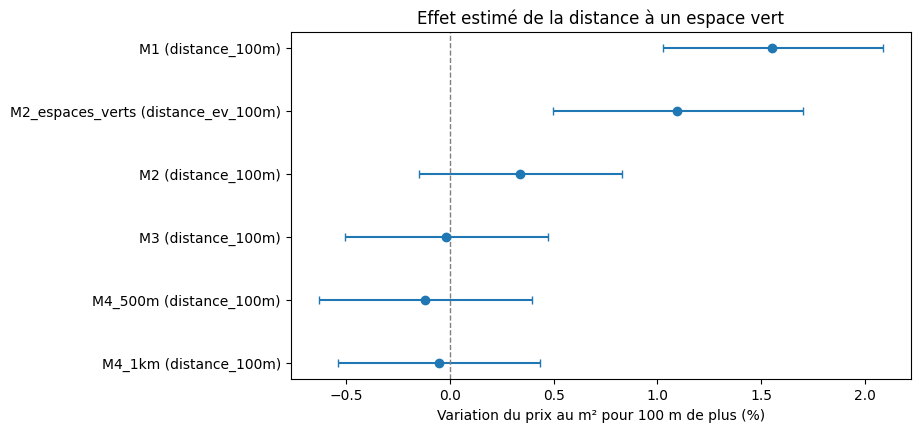

In [79]:
d = resultats[resultats["variable"].isin(["distance_ev_100m", "distance_100m"])].reset_index(drop=True)
y = np.arange(len(d))[::-1]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(
    d["effet_pct"], y, fmt="o", capsize=3,
    xerr=[d["effet_pct"] - d["effet_pct_bas"], d["effet_pct_haut"] - d["effet_pct"]],
)
ax.axvline(0, ls="--", lw=1, color="grey")
ax.set_yticks(y)
ax.set_yticklabels(d["modele"] + " (" + d["variable"] + ")")
ax.set_xlabel("Variation du prix au m² pour 100 m de plus (%)")
ax.set_title("Effet estimé de la distance à un espace vert")
os.makedirs("figures", exist_ok=True)
fig.savefig("figures/effet_distance.png", dpi=200, bbox_inches="tight")
plt.show()

### 3. Interprétation

Dans les 26 875 ventes retenues, **100 m d’éloignement supplémentaire du parc, jardin ou square le plus proche sont associés à un prix au m² supérieur de 1,55 %** dans la régression simple (M1). La distance seule explique 0,23 % de la variance du logarithme du prix au m². Lorsque l’on tient compte de la surface, du nombre de pièces, du trimestre de vente et de l’arrondissement (M2), l’écart tombe à **+0,34 %**. L’intervalle de confiance à 95 % va de −0,15 % à +0,83 % (*p* = 0,174). Les contrôles expliquent donc une partie de l’association brute, sans que cette comparaison permette d’attribuer l’atténuation à une variable précise.

**Le choix de l’inventaire compte.** Avec les mêmes contrôles et les mêmes ventes, la distance à l’espace le plus proche de l’inventaire élargi donne +1,08 % pour 100 m supplémentaires (IC à 95 % de +0,49 % à +1,67 %). Pourtant, le R² ajusté diffère à peine entre les deux versions de M2 (14,48 % contre 14,43 %). Les deux distances décrivent des voisinages différents. Le faible écart de R² ne permet pas de déterminer quel inventaire mesure le mieux l’accès à un parc public.

M3 compare les logements qui partagent le même site le plus proche, en conservant les contrôles de M2. L’écart estimé pour 100 m supplémentaires est alors de **−0,02 %** (IC à 95 % de −0,50 % à +0,47 %, *p* = 0,946). Les différences de niveau de prix entre les secteurs desservis par les différents sites contribuent à l’ajustement du modèle : le R² ajusté atteint 17,86 %. À l’intérieur de ces secteurs, le gradient moyen de prix selon la distance est proche de zéro.

**La surface cumulée apporte une autre mesure de proximité.** À distance au site le plus proche donnée, un hectare supplémentaire dans un rayon de 500 m est associé à −0,19 % sur le prix au m² (*p* = 0,261). Dans la variante à 1 km, l’estimation est de +0,16 % par hectare (IC à 95 % de −0,02 % à +0,33 %, *p* = 0,084). Aucun des deux coefficients de surface n’est significatif à 5 %. Dans ces deux modèles, le coefficient de distance reste faible (respectivement −0,12 % et −0,05 % par 100 m).

**Comparaison avec une étude immobilière.** En 2021, Meilleurs Agents rapporte pour Paris une surcote de 8,3 % à moins de cinq minutes d’un grand parc ou d’un jardin emblématique, relativement aux logements situés à plus de quinze minutes. L’étude retient seize sites parisiens et compare des classes de distance. Notre estimation porte sur une variation continue de 100 m autour d’un ensemble qui inclut aussi les squares. Une prime propre aux abords de quelques grands parcs peut donc coexister avec un gradient moyen proche de zéro dans notre échantillon. [Meilleurs Agents, étude d’octobre 2021, résultats et méthodologie](https://backyard-static.meilleursagents.com/press/ce696d4e0a48fcead74145d59aef59b94807f299.pdf)

## D. Tests de robustesse

Les résultats dépendent de choix : la façon de regrouper les écarts-types, la présence de prix extrêmes, la distance maximale au parc. Nous vérifions que le coefficient de `distance_100m` (modèles M2 et M3) change peu selon ces choix.

In [80]:
p1, p99 = ventes["prix_m2"].quantile([.01, .99])

variantes = {
    "Référence (groupé par parcelle)": (ventes, "id_parcelle"),
    "Groupé par parc le plus proche": (ventes, "nom_parc_proche"),
    "Prix entre les percentiles 1 et 99": (ventes[ventes["prix_m2"].between(p1, p99)], "id_parcelle"),
    "Ventes à moins de 1 000 m d'un parc": (ventes[ventes["dist_parc_m"] <= 1000], "id_parcelle"),
}

lignes = []
for nom_variante, (data, cluster) in variantes.items():
    for nom_modele in ["M2", "M3"]:
        m = estimer(formules[nom_modele], data, cluster)
        lignes.append({"variante": nom_variante, "modele": nom_modele, "n": int(m.nobs),
                       **{k: v for k, v in extraire(nom_modele, m)[0].items()
                          if k in ["coefficient", "p_value", "effet_pct", "effet_pct_bas", "effet_pct_haut"]}})

robustesse = pd.DataFrame(lignes)
robustesse.round(4)

,variante,modele,n,coefficient,p_value,effet_pct,effet_pct_bas,effet_pct_haut
0,Référence (groupé par parcelle),M2,26875,0.0034,0.1739,0.3381,-0.1488,0.8274
1,Référence (groupé par parcelle),M3,26875,-0.0002,0.9458,-0.0170,-0.5049,0.4733
2,Groupé par parc le plus proche,M2,26875,0.0034,0.3065,0.3381,-0.3090,0.9894
3,Groupé par parc le plus proche,M3,26875,-0.0002,0.9535,-0.0170,-0.5860,0.5554
4,Prix entre les percentiles 1 et 99,M2,26337,0.0053,0.0140,0.5343,0.1081,0.9624
5,Prix entre les percentiles 1 et 99,M3,26337,0.0024,0.2452,0.2416,-0.1656,0.6505
6,Ventes à moins de 1 000 m d'un parc,M2,26875,0.0034,0.1739,0.3381,-0.1488,0.8274
7,Ventes à moins de 1 000 m d'un parc,M3,26875,-0.0002,0.9458,-0.0170,-0.5049,0.4733


Le regroupement des erreurs par site autorise une corrélation entre des ventes rattachées au même parc, y compris sur des parcelles distinctes. Les coefficients restent identiques puisque les ventes et les variables explicatives sont les mêmes. Pour M2, l’intervalle à 95 % s’élargit de [−0,15 % ; +0,83 %] à [−0,31 % ; +0,99 %] par 100 m. Pour M3, il passe de [−0,50 % ; +0,47 %] à [−0,59 % ; +0,56 %]. La conclusion au seuil de 5 % est identique dans les deux cas.

L’exclusion des deux extrémités de la distribution des prix ramène l’échantillon à 26 337 ventes. **M2 est sensible à cette sélection** : l’écart atteint +0,53 % par 100 m et devient significatif à 5 % (*p* = 0,014). Dans M3, l’estimation passe à +0,24 %, avec un intervalle de −0,17 % à +0,65 % (*p* = 0,245). Le signe de M3 varie donc selon l’échantillon, tandis que les données restent compatibles avec un gradient nul autour d’un même site.

Enfin, les 26 875 ventes satisfont déjà le critère de distance de 1 km. Cette restriction reproduit exactement les résultats de référence et n’apporte aucune information supplémentaire sur leur robustesse.

### Enregistrement des résultats

In [81]:
os.makedirs("data/3.resultats", exist_ok=True)
resultats.to_csv("data/3.resultats/resultats_regressions.csv", index=False)
robustesse.to_csv("data/3.resultats/resultats_robustesse.csv", index=False)
print("Résultats enregistrés dans data/3.resultats")

Résultats enregistrés dans data/3.resultats


## E. Conclusion de la modélisation

Sur les ventes parisiennes de 2023 à 2025, nous ne mettons pas en évidence de prime moyenne de proximité lorsqu’on compare des appartements rattachés au même parc, jardin ou square. Pour deux logements comparables au regard des caractéristiques observées, l’écart de prix estimé pour 100 m d’éloignement est de −0,02 %, et l’intervalle à 95 % reste compris entre environ −0,5 % et +0,5 %. Ce résultat concerne un gradient moyen. Il laisse ouverte la possibilité d’une prime très localisée, par exemple pour un appartement donnant directement sur un parc.

L’interprétation reste descriptive. L’implantation des parcs et la composition du bâti varient entre quartiers. Les effets fixes par site absorbent les différences moyennes entre leurs secteurs, mais l’étage, l’état du logement, l’ascenseur, la vue ou le bruit peuvent encore varier à l’intérieur d’un même secteur. La distance à vol d’oiseau depuis la parcelle ignore également l’emplacement de l’entrée, les clôtures et les horaires. Deux logements situés à la même distance du contour peuvent ainsi offrir des accès très différents.

La portée de cette conclusion se limite aux ventes d’un seul appartement sans dépendance retenues dans Paris sur la période étudiée. Une prolongation naturelle consisterait à mesurer le trajet à pied jusqu’à une entrée et à distinguer les logements en bordure immédiate des autres logements du même secteur.